# Выбросы, типы, унификация

Анализ и структуры данных, 9 класс. Раздел 3.2, занятие 5. 10.11.2026.

## Как работать с ноутбуком

Сегодня пара без учителя: всё, что нужно, есть в этом ноутбуке. Он одновременно и конспект,
и практика.

- Читайте сверху вниз и запускайте ячейки по очереди (Shift + Enter). Ничего не пропускайте:
  следующие ячейки пользуются тем, что посчитали предыдущие.
- Перед ячейкой «**Что выведет?**» сначала ответьте сами, можно прямо в комментарии. Потом
  запустите ячейку и откройте разбор под ней.
- Объяснения займут минут сорок, остальное время — задачи. Задачи 1–5 обязательные,
  задача 6 со звёздочкой.
- Под каждой задачей есть проверки. Если всё верно, напечатается «Задача N: ок». Если проверка
  упала, прочитайте сообщение: в нём написано, какой случай не обработан.
- Застряли — вернитесь к блоку, на который ссылается задача, и посмотрите подсказку.
- В конце пары сохраните ноутбук и отправьте ссылку на него так же, как сдавали КР № 1.

## План

1. Первый взгляд: что не так с анкетой
2. Числа, записанные текстом
3. Даты
4. Один и тот же ответ, записанный по-разному
5. Выбросы и ошибки ввода
6. Протокол очистки

## Данные

Анкета «Сон и экранное время»: ученики 7–11 классов заполняли Google-форму. Набор учебный,
сгенерирован для занятия.

| Столбец | Вопрос анкеты |
|---|---|
| `timestamp` | когда отправлена форма (форма заполняет сама) |
| `grade` | ваш класс |
| `height` | ваш рост в сантиметрах |
| `sleep` | сколько часов вы спите в будни |
| `screen` | сколько часов в день проводите у экрана |
| `subject` | ваш любимый предмет |

На все вопросы, кроме первого, отвечали в свободном поле, и каждый писал как привык.
Запустите служебную ячейку: она создаст файл `anketa_raw.csv` и загрузит его в таблицу `raw`.

In [ ]:
#@title Служебная ячейка: создаёт файл anketa_raw.csv. Запустите её, разбираться не нужно.
import csv
import random

import matplotlib.pyplot as plt
import pandas as pd


def make_anketa(path="anketa_raw.csv", seed=911):
    """Учебная выгрузка анкеты «Сон и экранное время» со всеми её дефектами."""
    rnd = random.Random(seed)
    subjects = {
        "математика": ["Математика", "математика", "МАТЕМАТИКА", "матеша", "алгебра", "Алгебра",
                       "геометрия", "матан", "математика "],
        "информатика": ["Информатика", "информатика", "инфа", "Инфа", "информатика  ", "ИНФОРМАТИКА"],
        "физика": ["Физика", "физика", "физика "],
        "химия": ["Химия", "химия"],
        "биология": ["Биология", "биология", "био", "Биология "],
        "история": ["История", "история", "ИСТОРИЯ"],
        "русский язык": ["Русский язык", "русский", "Русский", "русский язык"],
        "литература": ["Литература", "литература", "литра", "Литра"],
        "английский язык": ["Английский язык", "английский", "Английский", "англ", "инглиш"],
        "физкультура": ["Физкультура", "физра", "Физра", "физ-ра", "физкультура"],
        None: ["нет", "никакой", "-", "все", "не знаю", "обед"],
    }
    weights = {"математика": 22, "информатика": 18, "физика": 7, "химия": 5, "биология": 7,
               "история": 8, "русский язык": 5, "литература": 6, "английский язык": 10,
               "физкультура": 9, None: 3}
    names = list(weights)
    rows = []
    for _ in range(354):
        number = rnd.choice([7, 8, 9, 10, 11])
        letter = rnd.choice("АБВ")

        # время заполнения формы: 3–9 ноября, чаще вечером
        day = rnd.randint(3, 9)
        hour = rnd.choices(range(8, 24), weights=[1, 1, 1, 2, 2, 3, 5, 6, 6, 6, 7, 8, 9, 9, 7, 4])[0]
        stamp = f"{day:02d}.11.2026 {hour:02d}:{rnd.randint(0, 59):02d}:{rnd.randint(0, 59):02d}"

        # класс
        r = rnd.random()
        lat = {"А": "A", "В": "B"}
        if r < 0.10:
            grade = f"{number}{letter.lower()}"
        elif r < 0.18:
            grade = f"{number} {letter}"
        elif r < 0.24:
            grade = f"{number}-{letter}"
        elif r < 0.29:
            grade = f" {number}{letter}"
        elif r < 0.33:
            grade = f"{number}{letter} "
        elif r < 0.37:
            grade = f"{number} {letter.lower()}"
        elif r < 0.43 and letter in lat:
            grade = f"{number}{lat[letter]}"          # латинская буква, похожая на русскую
        else:
            grade = f"{number}{letter}"

        # рост, см
        h = round(rnd.gauss(127 + 4 * number, 7))
        r = rnd.random()
        if r < 0.08:
            height = f"{h} см"
        elif r < 0.13:
            height = f"{h}см"
        elif r < 0.20:
            height = f"{h / 100:.2f}".replace(".", ",")
        elif r < 0.23:
            height = f"{h / 100:.2f}"
        elif r < 0.27:
            height = ""
        elif r < 0.28:
            height = "не знаю"
        else:
            height = str(h)

        # сон в будни, часов
        s = 8.5 - 0.35 * (number - 7) + rnd.gauss(0, 0.8)
        s = min(10.0, max(4.5, round(s * 2) / 2))
        whole = s == int(s)
        txt = str(int(s)) if whole else str(s).replace(".", ",")
        r = rnd.random()
        if r < 0.03:
            sleep = ""
        elif r < 0.11:
            sleep = txt + " ч"
        elif r < 0.15:
            sleep = txt + "ч"
        elif r < 0.19 and whole:
            sleep = txt + (" часа" if int(s) in (2, 3, 4) else " часов")
        elif r < 0.25 and not whole:
            sleep = str(s)                              # с точкой
        else:
            sleep = txt

        # экранное время в день, часов
        t = min(14.0, round(rnd.lognormvariate(1.45, 0.42) * 2) / 2)
        r = rnd.random()
        if r < 0.03:
            screen = ""
        elif t != int(t) and r < 0.75:
            screen = str(t).replace(".", ",")
        elif t == int(t):
            screen = str(int(t))
        else:
            screen = str(t)

        name = rnd.choices(names, weights=[weights[n] for n in names])[0]
        subject = rnd.choice(subjects[name])

        rows.append([stamp, grade, height, sleep, screen, subject])

    # ошибки ввода: вставлены в случайные строки
    def put(column, value):
        rows[rnd.randrange(len(rows))][column] = value

    for v in ["1650", "1720", "17"]:
        put(2, v)
    for v in ["восемь", "восемь", "много", "80", "75", "0", "24"]:
        put(3, v)
    for v in ["30", "100", "-2"]:
        put(4, v)

    # повторная отправка формы: 6 полных дубликатов
    for _ in range(6):
        k = rnd.randrange(len(rows))
        rows.insert(k + 1, list(rows[k]))

    rows.sort(key=lambda row: (row[0][:2], row[0][11:]))
    with open(path, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["timestamp", "grade", "height", "sleep", "screen", "subject"])
        writer.writerows(rows)
    return len(rows)


make_anketa("anketa_raw.csv")
raw = pd.read_csv("anketa_raw.csv")
print("версия pandas:", pd.__version__)
print("строк и столбцов:", raw.shape)

версия pandas: 2.2.3
строк и столбцов: (360, 6)


## 1. Первый взгляд: что не так с анкетой

Прежде чем что-то чинить, нужно понять, что сломано. Для этого хватает трёх вещей: посмотреть
на первые строки, на типы столбцов и на то, какие значения встречаются.

In [ ]:
raw.head(10)

,timestamp,grade,height,sleep,screen,subject
0,03.11.2026 08:11:07,8А,158 см,8,"6,5",информатика
1,03.11.2026 09:22:01,11а,178,"8,5",6,литература
2,03.11.2026 09:39:53,8Б,не знаю,"8,5",5,биология
3,03.11.2026 09:43:12,7А,NaN,"6,5",7,физика
4,03.11.2026 09:49:27,9 А,164,NaN,4,алгебра
5,03.11.2026 10:55:58,8В,154,"7,5",9,Информатика
6,03.11.2026 11:00:13,11В,164,"8,5",5.5,физика
7,03.11.2026 13:00:38,7 а,144,9,2.5,информатика
8,03.11.2026 13:11:38,7В,17,9,"5,5",Русский язык
9,03.11.2026 13:51:59,11В,"1,79","6,5",-2,ИСТОРИЯ


In [ ]:
raw.dtypes

,0
timestamp,object
grade,object
height,object
sleep,object
screen,object
subject,object


Все шесть столбцов — текст: тип `object`, в новых версиях pandas — `str`. Для класса
и любимого предмета это нормально. А вот рост, сон и экранное время должны быть числами.
Если pandas оставил такой столбец текстом, значит, хотя бы одно значение в нём он не смог
прочитать как число. Посмотрим, какие там бывают ответы.

In [ ]:
print(raw["height"].unique()[:40].tolist())

['158 см', '178', 'не знаю', nan, '164', '154', '144', '17', '1,79', '168', '162', '172', '171', '157', '1.53', '158', '1,51', '165см', '163', '179 см', '185', '147', '155', '159', '167', '169см', '1.49', '148', '165 см', '157 см', '171 см', '166', '156', '1.70', '149', '146', '1,70', '154 см', '174', '165']


Тут и «158 см», и «1,79» (это метры, да ещё с запятой), и «не знаю». С классом не лучше:
посчитаем, сколько разных вариантов записи.

In [ ]:
print("разных значений в grade:", raw["grade"].nunique())
print(sorted(raw["grade"].unique()))

разных значений в grade: 94
[' 10Б', ' 11Б', ' 11В', ' 7А', ' 7Б', ' 8А', ' 8Б', ' 8В', ' 9А', ' 9Б', ' 9В', '10 А', '10 Б', '10 В', '10 а', '10 б', '10 в', '10-А', '10-Б', '10-В', '10B', '10А', '10А ', '10Б', '10Б ', '10В', '10В ', '10а', '10б', '11 А', '11 Б', '11 В', '11 а', '11 б', '11 в', '11-А', '11-Б', '11-В', '11A', '11B', '11А', '11Б', '11Б ', '11В', '11В ', '11а', '11б', '11в', '7 А', '7 Б', '7 В', '7 а', '7-А', '7A', '7А', '7А ', '7Б', '7В', '7В ', '7а', '7б', '7в', '8 А', '8 Б', '8 В', '8 а', '8 в', '8-А', '8-Б', '8-В', '8B', '8А', '8А ', '8Б', '8Б ', '8В', '8а', '8б', '8в', '9 А', '9 Б', '9 В', '9 а', '9 б', '9 в', '9-А', '9А', '9Б', '9Б ', '9В', '9В ', '9а', '9б', '9в']


Классов в школе 15 (с 7 по 11, буквы А, Б, В), а вариантов записи почти сто: «10-А», «11а»,
«9 Б»… Кавычки в списке показывают и лишние пробелы: «' 7А'», «'10А '».

Ещё одно, что вы уже умеете: некоторые отправили форму дважды. Уберём полные дубликаты,
как 13 октября. Таблицу `raw` не трогаем: это исходные данные. Дальше работаем с `df`.

In [ ]:
print("полных дубликатов:", raw.duplicated().sum())
df = raw.drop_duplicates()
print("строк осталось:", len(df))

полных дубликатов: 6
строк осталось: 354


Что нашли, по столбцам:

| Столбец | Что не так | Блок |
|---|---|---|
| `height` | текст вместо чисел: «см», запятая, метры вперемешку с сантиметрами; есть странные числа | 2, 5 |
| `sleep`, `screen` | текст вместо чисел: «ч», «часов», запятая | задачи 1, 4, 5 |
| `timestamp` | дата записана текстом | 3 |
| `grade`, `subject` | один ответ записан десятком способов | 4 |

Такой список — начало протокола очистки, о нём в блоке 6.

## 2. Числа, записанные текстом

Начнём с вопроса.

In [ ]:
# Что выведет?
hours = pd.Series(["8", "7", "9"])
print(hours.sum())

879


<details>
<summary><b>Разбор</b> (откройте, когда подумаете сами)</summary>

`879`. Это строки, а сложение строк — склеивание: `"8" + "7" + "9"` даёт `"879"`. Ошибки нет,
и поэтому такая проблема опасна: число получилось, только бессмысленное. А `hours.mean()`
упадёт с ошибкой — среднее у строк не посчитать.

Отсюда правило: прежде чем что-то считать, проверьте тип столбца (`dtypes`).

</details>

Первое, что приходит в голову, — `astype(float)`. Но этот метод падает на первом же значении,
которое не похоже на число.

In [ ]:
try:
    df["height"].astype(float)
except ValueError as error:
    print("Ошибка:", error)

Ошибка: could not convert string to float: '158 см'


Есть функция `pd.to_numeric(столбец, errors="coerce")`. Она не падает: всё, что не смогла
прочитать как число, превращает в пропуск `NaN` (coerce — «принудить»). Удобно, но коварно.
Сравним, сколько пропусков было и сколько стало.

In [ ]:
h = pd.to_numeric(df["height"], errors="coerce")
print("пропусков было:", df["height"].isna().sum())
print("пропусков стало:", h.isna().sum())

пропусков было: 15
пропусков стало: 94


Пропусков стало намного больше: «158 см» и «1,65» для pandas не числа. Но это не настоящие
пропуски, человек свой рост указал. Поэтому порядок другой: **сначала починить текст, потом превращать
в число**. Строковые методы для целого столбца пишутся через `.str`:

- `.str.replace("см", "")` — убрать «см»;
- `.str.strip()` — убрать пробелы по краям;
- `.str.replace(",", ".")` — десятичная запятая → точка: Python понимает только точку.

In [ ]:
text = df["height"].str.replace("см", "").str.strip().str.replace(",", ".")
h = pd.to_numeric(text, errors="coerce")
print("пропусков стало:", h.isna().sum())

# что так и не прочиталось как число, хотя ответ был
print(df.loc[h.isna() & df["height"].notna(), "height"].unique().tolist())

пропусков стало: 16
['не знаю']


Остались только «не знаю» — честный пропуск. Теперь посмотрим на числа.

In [ ]:
h.describe()

,height
count,338.000000
mean,153.201213
std,129.636068
min,1.490000
25%,154.000000
50%,162.000000
75%,168.000000
max,1720.000000


Минимум меньше двух: это ответы в метрах (1,65 м). Рост в метрах всегда меньше 3, в сантиметрах
всегда больше 3, поэтому правило простое: если меньше 3 — умножить на 100. Так это записывается
через `where`: он оставляет значения там, где условие верно, а в остальных местах ставит
второй аргумент.

In [ ]:
h = h.where(h >= 3, h * 100)
h.describe()

,height
count,338.000000
mean,172.242604
std,117.530627
min,17.000000
25%,158.000000
50%,164.000000
75%,170.000000
max,1720.000000


Метры исправлены, но остались минимум 17 и максимум 1720 — к ним вернёмся в блоке 5.

Кстати, если в файле *все* дробные числа записаны через запятую, а других проблем нет,
можно сразу сказать об этом при загрузке: `pd.read_csv("файл.csv", decimal=",")`. У нас
в одном столбце и запятые, и «см», поэтому чиним вручную.

## 3. Даты

В столбце `timestamp` дата и время записаны текстом: `03.11.2026 08:11:07`. Чтобы узнать час
или день недели, его нужно превратить в настоящую дату. Это делает `pd.to_datetime`.

In [ ]:
# Что выведет? Подумайте, какой месяц получится
t = pd.to_datetime(df["timestamp"])
print(df["timestamp"].iloc[0], "->", t.iloc[0])
print("месяцы:", sorted(t.dt.month.unique().tolist()))

03.11.2026 08:11:07 -> 2026-03-11 08:11:07
месяцы: [3, 4, 5, 6, 7, 8, 9]


<details>
<summary><b>Разбор</b> (откройте, когда подумаете сами)</summary>

`03.11.2026` превратилось в 11 марта. Без подсказки pandas читает такую запись по-американски:
сначала месяц, потом день. Анкету заполняли с 3 по 9 ноября, все дни не больше 12, поэтому
каждая дата «нормально» прочиталась — и ни одной ошибки. Вместо одной недели ноября получилось
семь разных месяцев, с марта по сентябрь.

Самые неприятные ошибки в данных — те, при которых ничего не падает.

</details>

Поэтому формат даты лучше всегда указывать явно, параметром `format`:

| Код | Что значит | Пример |
|---|---|---|
| `%d` | день, две цифры | 03 |
| `%m` | месяц, две цифры | 11 |
| `%Y` | год, четыре цифры | 2026 |
| `%H` | часы | 08 |
| `%M` | минуты | 11 |
| `%S` | секунды | 07 |

Остальные символы формата пишутся как в самой записи: точки, пробел, двоеточия. Внимание:
`%m` — месяц, `%M` — минуты.

In [ ]:
t = pd.to_datetime(df["timestamp"], format="%d.%m.%Y %H:%M:%S")
print(df["timestamp"].iloc[0], "->", t.iloc[0])
print("месяцы:", sorted(t.dt.month.unique().tolist()))

03.11.2026 08:11:07 -> 2026-11-03 08:11:07
месяцы: [11]


Из настоящей даты можно доставать части через `.dt`: `.dt.day` — число, `.dt.month` — месяц,
`.dt.hour` — час, `.dt.dayofweek` — день недели (0 — понедельник). Посмотрим, в какое время
суток заполняли анкету.

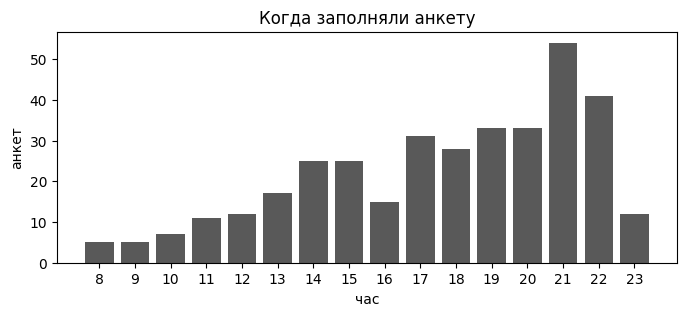

In [ ]:
by_hour = t.dt.hour.value_counts().sort_index()

plt.figure(figsize=(8, 3))
plt.bar(by_hour.index, by_hour.values, color="0.35")
plt.xlabel("час")
plt.ylabel("анкет")
plt.title("Когда заполняли анкету")
plt.xticks(range(8, 24))
plt.show()

Больше всего анкет пришло вечером, пик — в 21 час.

Если дата в записи невозможна (31 сентября), `to_datetime` упадёт. С `errors="coerce"` такая
дата станет пропуском `NaT` — это `NaN` для дат.

In [ ]:
pd.to_datetime(pd.Series(["31.09.2026", "30.09.2026"]), format="%d.%m.%Y", errors="coerce")

,0
0,NaT
1,2026-09-30


## 4. Один и тот же ответ, записанный по-разному

Вернёмся к классам: почти сто вариантов на 15 настоящих классов. Приводить их к одному виду
(унифицировать) будем по шагам и после каждого шага смотреть, сколько вариантов осталось.

In [ ]:
g = df["grade"]
print("как есть:", g.nunique())

g = g.str.strip()
print("без пробелов по краям:", g.nunique())

g = g.str.upper()
print("все буквы заглавные:", g.nunique())

g = g.str.replace(" ", "").str.replace("-", "")
print("без пробелов и дефисов внутри:", g.nunique())
print(sorted(g.unique()))

как есть: 94
без пробелов по краям: 72
все буквы заглавные: 46
без пробелов и дефисов внутри: 20
['10B', '10А', '10Б', '10В', '11A', '11B', '11А', '11Б', '11В', '7A', '7А', '7Б', '7В', '8B', '8А', '8Б', '8В', '9А', '9Б', '9В']


Осталось 20 вариантов, а должно быть 15. Присмотритесь к списку: «11А» встречается дважды.

In [ ]:
# Что выведет?
print("А" == "A")
print(ord("А"), ord("A"))

False
1040 65


<details>
<summary><b>Разбор</b> (откройте, когда подумаете сами)</summary>

`False`, а коды символов — 1040 и 65. Первая буква русская, вторая латинская. Выглядят они
одинаково, но для компьютера это разные символы, как «А» и «Я». Кто-то заполнял форму
с английской раскладкой. Таких двойников у русских букв много: А, В, Е, К, М, Н, О, Р, С, Т, Х.

</details>

Заменить латинские двойники на русские можно так: `str.maketrans` строит таблицу замен
«символ → символ», а `.str.translate` применяет её к каждому значению столбца.

In [ ]:
LATIN = str.maketrans("ABCEHKMOPTX", "АВСЕНКМОРТХ")   # латинская буква -> такая же на вид русская

g = g.str.translate(LATIN)
print("латиница заменена на кириллицу:", g.nunique())
print(g.value_counts().sort_index())

латиница заменена на кириллицу: 15
grade
10А    28
10Б    17
10В    25
11А    21
11Б    26
11В    32
7А     26
7Б     20
7В     16
8А     31
8Б     23
8В     24
9А     19
9Б     27
9В     19
Name: count, dtype: int64


Ровно 15 классов. Обратите внимание на порядок шагов: латинские двойники бывают и строчными
(«a»), поэтому заменяем их после `upper()`.

Бывает, что ответы различаются не записью, а словами: «матеша», «алгебра» и «Математика» —
это всё любимая математика. Здесь нужен словарь соответствий «как написали → как должно быть».
У столбца есть два похожих метода, которые принимают словарь.

In [ ]:
# Что выведет?
words = pd.Series(["инфа", "физика", "матеша"])
fix = {"инфа": "информатика", "матеша": "математика"}
print(words.replace(fix).tolist())
print(words.map(fix).tolist())

['информатика', 'физика', 'математика']
['информатика', nan, 'математика']


<details>
<summary><b>Разбор</b> (откройте, когда подумаете сами)</summary>

```
['информатика', 'физика', 'математика']
['информатика', nan, 'математика']
```

`replace` заменяет то, что есть в словаре, а остальное оставляет как было. `map` переводит
каждое значение по словарю, и всё, чего в словаре нет, становится `NaN` — даже правильная
«физика». Для унификации нужен `replace`. А `map` полезен, чтобы найти ответы, которые
вы в словарь забыли: они как раз и станут `NaN`.

</details>

Последнее про текстовые столбцы. Если в столбце немного разных значений и они повторяются,
его удобно хранить как категорию: `astype("category")`. Каждое значение хранится один раз,
а в строках — только номера. Памяти нужно меньше.

In [ ]:
print("текст, байт:    ", g.memory_usage(deep=True))
print("категория, байт:", g.astype("category").memory_usage(deep=True))

текст, байт:     29475
категория, байт: 4870


## 5. Выбросы и ошибки ввода

После блока 2 в росте остались минимум 17 и максимум 1720 сантиметров. Это два разных случая,
которые важно не путать.

**Ошибка ввода** — значение, которое не может быть правдой: рост 1720 см, сон 80 часов,
30 часов у экрана в сутки. Если понятно, как исправить, исправляем, как метры в блоке 2.
Если непонятно (1720 — это 172 или 1,72 м?), заменяем на `NaN`: лучше честный пропуск,
чем выдуманное число.

**Выброс** — значение, которое сильно отличается от остальных, но вполне возможно: рост 191 см
у одиннадцатиклассника. Это настоящий человек, и обычно его оставляют в данных.

Ошибки ищут по здравому смыслу: заранее решаем, какие значения возможны. Для роста школьника
пусть это будет от 100 до 230 см.

In [ ]:
print("вне 100–230 см:", h[(h < 100) | (h > 230)].tolist())
print("до:    среднее", round(h.mean(), 1), " медиана", h.median())

h = h.where((h >= 100) & (h <= 230))      # невозможное -> NaN
print("после: среднее", round(h.mean(), 1), " медиана", h.median())

вне 100–230 см: [17.0, 1720.0, 1650.0]
до:    среднее 172.2  медиана 164.0
после: среднее 163.7  медиана 164.0


Три ошибки сдвинули средний рост больше чем на 8 сантиметров, а медиана не изменилась.
Медиана почти не чувствует редкие выбросы и ошибки, а среднее чувствует сильно.

Выбросы ищут по **правилу межквартильного размаха** — тому же, что в задаче про долгие попытки
в КР № 1:

1. $Q_1$ и $Q_3$ — первый и третий квартили: четверть значений меньше $Q_1$, четверть больше $Q_3$.
2. Межквартильный размах $IQR = Q_3 - Q_1$: ширина «средней половины» данных.
3. Границы: $Q_1 - 1{,}5 \cdot IQR$ и $Q_3 + 1{,}5 \cdot IQR$. Всё, что за ними, — кандидат в выбросы.

In [ ]:
q1 = h.quantile(0.25)
q3 = h.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print("Q1 =", q1, " Q3 =", q3, " IQR =", iqr)
print("границы:", low, "и", high)

# кто за границами: класс берём уже исправленный, из блока 4
pd.DataFrame({"класс": g, "рост": h})[(h < low) | (h > high)]

Q1 = 158.0  Q3 = 170.0  IQR = 12.0
границы: 140.0 и 188.0


,класс,рост
120,11В,191.0
311,10А,189.0


За границами двое: ученики 10 и 11 класса ростом 189 и 191 см. Это не ошибки, просто высокие
старшеклассники. Правило лишь показывает, на что посмотреть; решает человек.

Те же границы рисует «ящик с усами» (`plt.boxplot`): ящик — от $Q_1$ до $Q_3$, линия внутри —
медиана, усы доходят до самых дальних значений внутри границ, а точки за усами — выбросы.

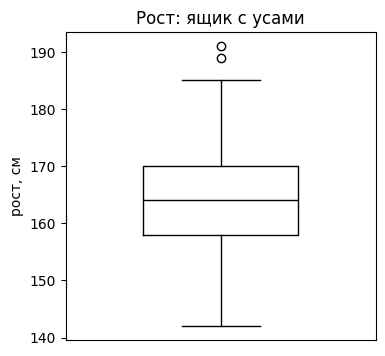

In [ ]:
plt.figure(figsize=(4, 4))
plt.boxplot(h.dropna(), widths=0.5, medianprops={"color": "black"})
plt.ylabel("рост, см")
plt.xticks([])
plt.title("Рост: ящик с усами")
plt.show()

Что делать с выбросом, зависит от вопроса:

- **оставить** — обычный выбор, это настоящие данные;
- считать **медиану** вместо среднего, если выбросы мешают;
- добавить **флаг** «выброс» отдельным столбцом, как флаг пропуска 13 октября;
- **удалить** — только если есть причина, и обязательно записать это в протокол.

## 6. Протокол очистки

Через неделю придёт новая выгрузка анкеты. Или учитель спросит: «Почему у тебя 354 ответа,
а не 360? Куда делись три значения роста?» Чтобы ответить и чтобы повторить очистку за секунду,
соблюдают три правила.

1. **Исходный файл не меняют.** Результат сохраняют в новый файл.
2. **Вся очистка — одна функция**, которую можно запустить заново на новой выгрузке.
3. **Каждый шаг записывают в протокол:** что сделали и сколько строк или значений это затронуло.

Соберём всё, что сделали в блоках 1–5, в функции.

In [ ]:
LATIN = str.maketrans("ABCEHKMOPTX", "АВСЕНКМОРТХ")


def fix_grade(s):
    """Класс к виду «9А»: без пробелов и дефисов, заглавная русская буква."""
    s = s.str.strip().str.upper().str.replace(" ", "").str.replace("-", "")
    return s.str.translate(LATIN)


def fix_height(s):
    """Рост в сантиметрах: «см» и запятая убраны, метры переведены, невозможное — NaN."""
    text = s.str.replace("см", "").str.strip().str.replace(",", ".")
    h = pd.to_numeric(text, errors="coerce")
    h = h.where(h >= 3, h * 100)
    return h.where((h >= 100) & (h <= 230))


def clean_part(raw):
    """Очистка дубликатов, класса, роста и времени. Возвращает таблицу и протокол."""
    protocol = []
    df = raw.drop_duplicates().copy()
    protocol.append(f"удалены полные дубликаты: {len(raw) - len(df)} строк")

    before = df["grade"].nunique()
    df["grade"] = fix_grade(df["grade"])
    protocol.append(f"класс приведён к виду «9А»: вариантов было {before}, стало {df['grade'].nunique()}")

    before = df["height"].isna().sum()
    df["height"] = fix_height(df["height"])
    protocol.append(f"рост переведён в числа (см): новых пропусков {df['height'].isna().sum() - before}")

    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%d.%m.%Y %H:%M:%S")
    protocol.append("время отправки переведено в даты, формат ДД.ММ.ГГГГ чч:мм:сс")
    return df, protocol


part, protocol = clean_part(raw)
for step in protocol:
    print("-", step)

- удалены полные дубликаты: 6 строк
- класс приведён к виду «9А»: вариантов было 94, стало 15
- рост переведён в числа (см): новых пропусков 4
- время отправки переведено в даты, формат ДД.ММ.ГГГГ чч:мм:сс


Протокол читается как отчёт: видно, что сделали и чего это стоило. Новые пропуски в росте —
это «не знаю» и три ошибки ввода из блока 5; остальные пропуски были с самого начала.
А `raw` при этом не изменился. Запустите ячейку ещё раз — получится то же самое: очистка
воспроизводима.

Сохраняют результат в новый файл, рядом с исходным:

```python
clean.to_csv("anketa_clean.csv", index=False)
```

Это сделаете в задаче 6, когда почистите все столбцы.

## Итоги

- Прежде чем считать, проверьте тип столбца: числа, записанные текстом, складываются склеиванием.
- `pd.to_numeric(..., errors="coerce")` превращает в `NaN` всё, что не число. Сначала почините
  текст (`.str.replace`, `.str.strip`), потом превращайте, и сравните число пропусков до и после.
- Даты — `pd.to_datetime` с явным `format`: без него 03.11 молча становится 11 марта.
- Унификация текста — по шагам: `strip`, `upper` или `lower`, лишние символы, латинские двойники.
  Синонимы — словарём через `replace`; `map` превращает в `NaN` всё, чего нет в словаре.
- Ошибка ввода невозможна — исправляем или ставим `NaN`. Выброс возможен — обычно оставляем.
  Кандидаты в выбросы — за границами $Q_1 - 1{,}5 \cdot IQR$ и $Q_3 + 1{,}5 \cdot IQR$.
- Исходный файл не трогаем, очистка — одна функция, каждый шаг — в протокол.

**Что дальше.** По плану — форматы хранения данных: CSV, JSON, электронные таблицы и как
их правильно загружать.

Теперь задачи. Если что-то забылось, номер блока указан в условии.

# Задачи

Правило то же, что 13 октября: функция **возвращает новый столбец** и не меняет то, что ей
передали. Проверки под задачами это проверяют.

Задачи 1–5 обязательные, 6 — со звёздочкой.

## Задача 1. Часы из текста (блок 2)

В столбцах `sleep` и `screen` ответы про часы записаны по-разному: «8», «7,5», «8 ч», «6ч»,
«9 часов», «4 часа», «7.5». Напишите функцию `to_hours(s)`, которая возвращает новый столбец
с числами. То, что числом не является («восемь», «много», пропуск), должно стать `NaN`.

```
to_hours(pd.Series(["8", "7,5", "8 ч", "9 часов", "восемь"]))
->  [8.0, 7.5, 8.0, 9.0, NaN]
```

*Подсказка:* сделайте так же, как с ростом в блоке 2. Подумайте, в каком порядке убирать
«часов», «часа» и «ч»: если первой убрать «ч», от «9 часов» останется «9 асов».

In [ ]:
def to_hours(s: pd.Series) -> pd.Series:
    """Новый столбец: ответы про часы, превращённые в числа; что не прочиталось — NaN."""
    text = (
        s.str.lower()
         .str.replace("часов", "", regex=False)
         .str.replace("часа", "", regex=False)
         .str.replace("ч", "", regex=False)
         .str.replace(",", ".", regex=False)
         .str.strip()
    )
    return pd.to_numeric(text, errors="coerce")
    pass

In [ ]:
# проверка задачи 1
answers = pd.Series(["8", "7,5", "8 ч", "6ч", "9 часов", "4 часа", " 7.5 ", "восемь", None])
backup = answers.copy()
res = to_hours(answers)
assert res is not None, "функция ничего не вернула: не забыли return?"
assert pd.api.types.is_numeric_dtype(res), "в ответе должны быть числа, а не текст: не забыли pd.to_numeric?"
assert res.iloc[0] == 8 and res.iloc[1] == 7.5, "«7,5» — это 7.5: замените запятую на точку"
assert res.iloc[2] == 8 and res.iloc[3] == 6, "«8 ч» и «6ч» — это 8 и 6: уберите «ч»"
assert res.iloc[4] == 9 and res.iloc[5] == 4, \
    "«9 часов» и «4 часа» — это 9 и 4. Если первой убрать «ч», от «часов» останется «асов»"
assert res.iloc[6] == 7.5, "« 7.5 » с пробелами по краям — это 7.5"
assert res.iloc[7:].isna().all(), "то, что не число («восемь», пропуск), должно стать NaN"
assert answers.equals(backup), "исходный столбец изменился, а не должен"
assert to_hours(df["sleep"]).isna().sum() == 17, \
    "на настоящих данных пропусков не столько, сколько должно быть: посмотрите, какие ответы не прочитались"
print("Задача 1: ок")

Задача 1: ок


## Задача 2. Анкеты по дням (блок 3)

Напишите функцию `forms_per_day(s)`: она получает столбец с временем отправки в виде
`ДД.ММ.ГГГГ чч:мм:сс` и возвращает, сколько анкет пришло в каждый день. Индекс ответа — число
месяца (3, 4, 5…), значения — количество анкет, по возрастанию чисел.

```
forms_per_day(pd.Series(["03.11.2026 21:15:07", "09.11.2026 08:00:00", "03.11.2026 22:40:31"]))
->  3    2
    9    1
```

*Подсказка:* `pd.to_datetime` с форматом, потом `.dt.day`, `value_counts()` и `sort_index()`.

In [ ]:
def forms_per_day(s: pd.Series) -> pd.Series:
    """Сколько анкет пришло в каждый день: индекс — число месяца, по возрастанию."""
    t = pd.to_datetime(s, format="%d.%m.%Y %H:%M:%S")
    return t.dt.day.value_counts().sort_index()
    pass

In [ ]:
# проверка задачи 2
stamps = pd.Series(["03.11.2026 21:15:07", "09.11.2026 08:00:00", "03.11.2026 22:40:31", "05.11.2026 14:02:59"])
backup = stamps.copy()
res = forms_per_day(stamps)
assert res is not None, "функция ничего не вернула: не забыли return?"
assert res.index.tolist() != [11], "получилось только 11-е число: pandas прочитал 03.11 как 11 марта. Укажите format"
assert res.index.tolist() == [3, 5, 9], "индекс — числа месяца по возрастанию: 3, 5, 9"
assert res.tolist() == [2, 1, 1], "3 ноября пришло две анкеты, 5 и 9 — по одной"
assert stamps.equals(backup), "исходный столбец изменился, а не должен"
assert forms_per_day(pd.Series(["12.11.2026 10:00:00", "13.11.2026 10:00:00"])).index.tolist() == [12, 13]
real = forms_per_day(df["timestamp"])
assert real.index.tolist() == [3, 4, 5, 6, 7, 8, 9] and real.sum() == len(df)
print("Задача 2: ок")
print(real)

Задача 2: ок
timestamp
3    63
4    53
5    48
6    51
7    43
8    55
9    41
Name: count, dtype: int64


## Задача 3. Любимый предмет (блок 4)

В столбце `subject` одни и те же предметы записаны по-разному: «Математика», «матеша», « инфа »,
«ФИЗИКА». Напишите функцию `fix_subject(s)`, которая возвращает новый столбец:

1. пробелы по краям убраны, все буквы строчные;
2. синонимы заменены по словарю `SUBJECTS` (он уже в ячейке);
3. всё, чего нет в списке `CANON` («нет», «все», «обед»), заменено словом `"другое"`.

```
fix_subject(pd.Series(["Математика", " инфа ", "физра", "нет"]))
->  ["математика", "информатика", "физкультура", "другое"]
```

*Подсказка:* в блоке 4 есть «Что выведет?» про `replace` и `map` — перечитайте разбор.
Пункт 3 — снова `where` с условием `.isin(CANON)`.

In [ ]:
SUBJECTS = {
    "матеша": "математика", "матан": "математика", "алгебра": "математика", "геометрия": "математика",
    "инфа": "информатика", "био": "биология", "русский": "русский язык", "литра": "литература",
    "английский": "английский язык", "англ": "английский язык", "инглиш": "английский язык",
    "физра": "физкультура", "физ-ра": "физкультура",
}
CANON = ["математика", "информатика", "физика", "химия", "биология", "история",
         "русский язык", "литература", "английский язык", "физкультура"]


def fix_subject(s: pd.Series) -> pd.Series:
    """Новый столбец: предмет строчными буквами из списка CANON или "другое"."""
    x = s.str.strip().str.lower()
    x = x.replace(SUBJECTS)
    return x.where(x.isin(CANON), "другое")
    pass

In [ ]:
# проверка задачи 3
answers = pd.Series(["Математика", "ФИЗИКА", "химия", "матеша", "физра", " инфа ", "литра ", "нет", "обед"])
backup = answers.copy()
res = fix_subject(answers)
assert res is not None, "функция ничего не вернула: не забыли return?"
assert res.iloc[:3].tolist() == ["математика", "физика", "химия"], \
    "«Математика» → «математика», «ФИЗИКА» → «физика». Если вышло NaN или «другое» — посмотрите разбор про map"
assert res.iloc[3:5].tolist() == ["математика", "физкультура"], "синонимы заменяются по словарю SUBJECTS"
assert res.iloc[5:7].tolist() == ["информатика", "литература"], "сначала уберите пробелы по краям, потом заменяйте по словарю"
assert res.iloc[7:].tolist() == ["другое", "другое"], "ответы, которых нет в CANON, — «другое»"
assert answers.equals(backup), "исходный столбец изменился, а не должен"
real = fix_subject(df["subject"])
assert sorted(real.unique()) == sorted(CANON + ["другое"]), "на настоящих данных должно остаться 11 вариантов"
print("Задача 3: ок")
print(real.value_counts())

Задача 3: ок
subject
математика         79
информатика        64
английский язык    33
физика             30
литература         27
история            26
русский язык       24
биология           23
физкультура        23
химия              16
другое              9
Name: count, dtype: int64


## Задача 4. Невозможные значения (блок 5)

Напишите функцию `impossible_to_nan(s, low, high)`: она получает числовой столбец и возвращает
новый, в котором значения меньше `low` или больше `high` заменены на `NaN`. Сами границы
допустимы. Пропуски остаются пропусками.

```
impossible_to_nan(pd.Series([7.0, 0.0, 24.0, 3.0, 14.0]), 3, 14)
->  [7.0, NaN, NaN, 3.0, 14.0]
```

*Подсказка:* в блоке 5 так чистили рост.

In [ ]:
def impossible_to_nan(s: pd.Series, low: float, high: float) -> pd.Series:
    """Новый столбец: значения вне отрезка [low, high] заменены на NaN."""
    return s.where((s >= low) & (s <= high))
    pass

In [ ]:
# проверка задачи 4
values = pd.Series([7.0, 0.0, 24.0, 3.0, 14.0, None, 80.0])
backup = values.copy()
res = impossible_to_nan(values, 3, 14)
assert res is not None, "функция ничего не вернула: не забыли return?"
assert len(res) == len(values), "строки удалять не нужно: невозможное значение заменяется на NaN"
assert res.iloc[3] == 3 and res.iloc[4] == 14, "границы допустимы: 3 и 14 часов сна — возможно"
assert res.isna().tolist() == [False, True, True, False, False, True, True], "0, 24 и 80 должны стать NaN"
assert res.iloc[0] == 7, "нормальные значения не меняются"
assert values.equals(backup), "исходный столбец изменился, а не должен"

# экранное время на настоящих данных: в сутках не больше 24 часов
screen = pd.to_numeric(df["screen"].str.replace(",", "."), errors="coerce")
fixed = impossible_to_nan(screen, 0, 24)
assert fixed.isna().sum() == screen.isna().sum() + 3, "в экранном времени три невозможных значения"
print("Задача 4: ок")
print("невозможное экранное время:", screen[fixed.isna() & screen.notna()].tolist())

Задача 4: ок
невозможное экранное время: [-2.0, 30.0, 100.0]


## Задача 5. Границы выбросов (блок 5)

Напишите функцию `iqr_bounds(s)`, которая возвращает пару чисел — нижнюю и верхнюю границы
выбросов по правилу межквартильного размаха: $Q_1 - 1{,}5 \cdot IQR$ и $Q_3 + 1{,}5 \cdot IQR$.
Пропуски не учитываются (`quantile` сам их пропускает).

```
iqr_bounds(pd.Series([2, 4, 4, 5, 6, 7, 30]))   ->  (0.25, 10.25)
```

Здесь $Q_1 = 4$, $Q_3 = 6{,}5$, $IQR = 2{,}5$. Вернуть пару можно так: `return low, high`.

In [ ]:
def iqr_bounds(s: pd.Series) -> tuple:
    """Границы выбросов: (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)."""
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr
    pass

In [ ]:
# проверка задачи 5
res = iqr_bounds(pd.Series([2, 4, 4, 5, 6, 7, 30]))
assert res is not None, "функция ничего не вернула: не забыли return?"
low, high = res
assert abs(low - 0.25) < 1e-9 and abs(high - 10.25) < 1e-9, \
    "для примера из условия должно быть (0.25, 10.25); квартили считайте через quantile"
low, high = iqr_bounds(pd.Series([1.0, 2.0, None, 3.0, 4.0]))
assert abs(low - (-0.5)) < 1e-9 and abs(high - 5.5) < 1e-9, "пропуск не учитывается: Q1 = 1.75, Q3 = 3.25"
print("Задача 5: ок")

# экранное время: кто за границами
screen = impossible_to_nan(pd.to_numeric(df["screen"].str.replace(",", "."), errors="coerce"), 0, 24)
low, high = iqr_bounds(screen)
print("границы:", low, "и", high)
pd.DataFrame({"класс": fix_grade(df["grade"]), "часов у экрана": screen})[screen > high]

Задача 5: ок
границы: -1.5 и 10.5


,класс,часов у экрана
20,9В,13.5
337,8Б,11.0


**Вопрос.** Посмотрите на результат. Почему нижняя граница отрицательная и что это говорит
о данных? Ошибки ли эти выбросы сверху?

<details>
<summary><b>Ответ</b> (откройте, когда подумаете сами)</summary>

Нижняя граница $-1{,}5$ часа: снизу выбросов не может быть совсем, меньше нуля часов не бывает.
Так получается, когда данные «скошены»: большинство значений собрано внизу (3–6 часов),
а вверх тянется длинный хвост. Сверху два ученика: 11 и 13,5 часа у экрана в день. Это много,
но возможно, поэтому это выбросы, а не ошибки, — оставляем. Ошибки (30, 100 и −2 часа)
мы убрали ещё в задаче 4.

</details>

## Задача 6 ★. Полная очистка (блок 6)

Напишите функцию `clean_all(raw)`, которая чистит всю анкету и возвращает новую таблицу
с теми же шестью столбцами:

- дубликаты, класс, рост и время — как в `clean_part` из блока 6. Её можно просто вызвать:
  `df, protocol = clean_part(raw)`;
- `sleep` — числа из задачи 1, допустимо от 3 до 14 часов, остальное — `NaN`;
- `screen` — числа из задачи 1 (она подходит и сюда), допустимо от 0 до 24 часов;
- `subject` — как в задаче 3.

Таблицу `raw` не меняйте. По желанию дополните протокол из `clean_part` своими шагами и напечатайте его.

In [ ]:
def clean_all(raw: pd.DataFrame) -> pd.DataFrame:
    """Вся анкета очищена: дубликаты, класс, рост, время, сон, экран, предмет."""
    clean, protocol = clean_part(raw)

    clean["sleep"] = impossible_to_nan(to_hours(clean["sleep"]), 3, 14)
    clean["screen"] = impossible_to_nan(to_hours(clean["screen"]), 0, 24)
    clean["subject"] = fix_subject(clean["subject"])

    return clean[["timestamp", "grade", "height", "sleep", "screen", "subject"]]
    pass

In [ ]:
# проверка задачи 6
backup = raw.copy()
clean = clean_all(raw)
assert clean is not None, "функция ничего не вернула: не забыли return?"
assert raw.equals(backup), "таблица raw изменилась, а не должна: работайте с копией"
assert list(clean.columns) == ["timestamp", "grade", "height", "sleep", "screen", "subject"], "столбцы те же, в том же порядке"
assert len(clean) == 354, "дубликаты удалены?"
assert clean["grade"].nunique() == 15, "классов должно быть 15"
assert pd.api.types.is_datetime64_any_dtype(clean["timestamp"]), "timestamp — даты"
assert clean["height"].notna().sum() == 335 and clean["height"].between(100, 230).sum() == 335, "рост — как в fix_height"
assert clean["sleep"].notna().sum() == 333, "сон: числа из задачи 1, вне 3–14 часов — NaN"
assert clean["sleep"].max() <= 14 and clean["sleep"].min() >= 3, "сон: допустимо от 3 до 14 часов"
assert clean["screen"].notna().sum() == 338 and clean["screen"].max() == 13.5, "экран: допустимо от 0 до 24 часов"
assert clean["subject"].nunique() == 11, "предметов 10 из CANON и «другое»"

clean.to_csv("anketa_clean.csv", index=False)     # результат — в новый файл, исходный не трогаем
print("Задача 6: ок, сохранено в anketa_clean.csv")
clean.describe()

Задача 6: ок, сохранено в anketa_clean.csv


,timestamp,height,sleep,screen
count,354,335.000000,333.000000,338.000000
mean,2026-11-06 13:34:53.285310720,163.674627,7.771772,4.803254
min,2026-11-03 08:11:07,142.000000,5.000000,1.500000
25%,2026-11-04 17:33:47.249999872,158.000000,7.000000,3.000000
50%,2026-11-06 14:15:41,164.000000,7.500000,4.500000
75%,2026-11-08 14:21:14.500000,170.000000,8.500000,6.000000
max,2026-11-09 23:45:08,191.000000,10.000000,13.500000
std,NaN,9.010894,0.953994,2.046685
